## Практическое домашнее задание 2. Градиентный спуск своими руками

### Общая информация

Дата выдачи: 16.10.2026

Мягкий дедлайн: 16.11.2026 23:59 MSK

Жесткий дедлайн: 23.11.2026 23:59 MSK


### Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). **Максимально допустимая оценка за работу — 10 баллов.**

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо считываемые диаграммы.

Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже.

**Максимальная оценка по набору решённых задач: 10/10** (1 + 4 + 1 + 1.5 + 1 + 0.5 + 1).


### О задании

В данном задании необходимо реализовать обучение линейной регрессии с помощью различных модификаций градиентного спуска. В файле `descents.py` вам нужно будет реализовать несколько классов для различных вариаций градиентного спуска, а именно:
* `VanillaGradientDescent`
* `StochasticGradientDescent`
* `SAGDescent`
* `MomentumDescent`
* `Adam`


В файле `linear_regression.py` вам необходимо будет реализовать класс `CustomLinearRegression` для обучения линейной регрессии (и, разумеется, предсказания целевой переменной на основе обученной модели).


### Про предложенную архитектуру

Предложенная вам архитектура шаблонов написана по принципам SOLID: основная ее идея в том, что вы сможете использовать различные лоссы и оптимизаторы с одним и тем же кодом прочих классов, никак не изменяя и не переписывая методы классов, которые с оптимизаторами и лоссом взаимодействуют. Мы добиваемся этого при помощи выделения интерфейсов (в Python мы достигаем этого при помощи абстрактных классов, см дальше в заданиях) и выделения зон ответственности каждого класса.

Глобально в нашей архитектуре всего 4 интерфейса (некоторые из которых на самом деле сразу concrete классы), каждый из которых порождает одно семейство:
- `interfaces.LossFunction`
  - Классы, имплементирующие этот интерфейс, отвечают за одну конкретную функцию потерь, используемую при обучении, и всё, что меняется вместе с ней при её замене: подсчёт лосса, подсчет градиента и аналитическое решение (если есть, то добавляется в интерфейс соответствующим mixin-ом).
- `interfaces.LinearRegressionInterface`
  - Интерфейс обертки для модели линейной регрессии, контейнер, содержащий составные части (лосс-функцию и оптимизатор) и использующий их для выполнения содержательной работы.
- `interfaces.LearningRateSchedule`
 - Простенькое семейство расписаний, определяющих шаг обучения для каждой итерации
- `interfaces.AbstractOptimizer`.
  -  Классы, имплементирующие этот интерфейс, имплементируют конкретный алгоритм оптимизации и всё, что происходит в его процессе. Пользуются обёрткой линейной регрессии для доступа к данным и вызова расчетов, чтобы не зависеть напрямую от конкретных функций потерь и шедулеров шага обучения.

Концепция передачи маленьких объектов, отвечающих за свою маленькую зону ответственности внутрь более сложного объекта для выполнения ими составных частей работы называется Dependency Injection, и работает как раз за счет выделения зоны ответственности и опоры на интерфейс вместо реализации.

Посмотрите на код `linear_regression.CustomLinearRegression`: она принимает в себя объекты с интерфейсами `LossFunction` и `AbstractOptimizer`, а в `descents.BaseDescent` как уточнении интерфейса абстрактного оптимизатора до итеративных оптимизаторов видно, что он в свою очередь принимает при инициализации объект шедулера шага обучения.

Благодаря этому, код, который использует эти классы, может по очереди:
- Инициализировать нужный шедулер с нужными параметрами для задания шага обучения
- Иницализировать оптимизатор, задав ему нужные параметры процесса и передав готовый шедулер
- Инициализировать класс линейной регрессии нужной под задачу функцией потерь и уже готовым оптимизатором.
- Запустить процесс обучения

И на любом этапе можно использовать другой объект с подходящим интерфейсом, и всё будет работать!


**В ходе выполнения этой домашки вы наполните все эти семейства классов различными имплементациями и будете менять их на ходу как перчатки!**

Более подробно про наследование классов в Python можно прочитать здесь:
* Наследование: https://docs.python.org/3/tutorial/classes.html#inheritance
* Абстрактные классы: https://docs.python.org/3/library/abc.html



## Задание 1. Линейная регрессия  (1 балл)

### Градиент функции потерь MSE

### Задание 1.0. Градиент MSE в матричном виде (0.3 балла).

Напомним, что функция потерь MSE записывается как:

$$
    Q(w) = \frac{1}{\ell} \sum \limits_{i = 1}^\ell (y_i - \langle x_i, w \rangle)^2 = \frac{1}{\ell} \| X w - y \|^2
$$

где $\ell$ – количество объектов в выборке, $X \in \mathbb{R}^{\ell \times d}$ – матрица "объект-признак", а $y \in \mathbb{R}^\ell$ – целевая переменная. Через $x_i$ обозначается $i$-ая строчка матрицы $X$, отвечающая за $i$-й объект выборки.

- **Выпишите ниже градиент для функции потерь MSE в матричном виде.**

**Решение:**

Обозначим $r=Xw-y$. Тогда
$$dQ=\frac1\ell d(r^Tr)=\frac2\ell r^T X\,dw,$$
поэтому
$${\nabla_w Q(w)=\frac2\ell X^T(Xw-y)}.$$
Размерность градиента — $d$, как и у вектора весов.


- **Имплементируйте методы `MSELoss.loss`, `MSELoss.gradient`**

### Задание 1.1 Аналитическое решение и `CustomLinearRegression` (0.7 балла)

Перед тем, как мы углубимся в итеративные методы оптимизации, давайте вспомним, что для ряда функций потерь существует и аналитическое решение. Давайте сперва вспомним, как оно выглядит для MSE.

- **Выведите формулу оптимальных $w$ в задаче минимизации MSE, и запишите её ниже.**

- **Имплементируйте подсчет этого решения в `MSELoss._plain_analytic_solution`**

$$\text{MSE} = \| X w - y \|^2$$
Из условия стационарности
$$X^T(Xw-y)=0 \quad\Longrightarrow\quad X^TXw=X^Ty.$$
При полном столбцовом ранге
$${w_*=(X^TX)^{-1}X^Ty}.$$
В коде решаем систему через `np.linalg.solve`, не вычисляя обратную матрицу явно.

**Ответ.** Формирование $X^TX$ требует $O(nd^2)$ операций и $O(d^2)$ памяти, решение системы — $O(d^3)$. При большом количестве признаков это дорого. При линейной зависимости столбцов обратная матрица не существует, а при близкой зависимости решение численно неустойчиво: число обусловленности $X^TX$ равно квадрату числа обусловленности $X$. Для таких случаев предпочтительны SVD/QR или регуляризация.

Теперь прокинем это решение в наш класс линейной регрессии, чтобы получше разобраться в архитектуре.


- **Допишите класс `descents.AnalyticSolutionOptimizer`**
- **Допишите класс `CustomLinearRegression`**
  - В нем на текущем этапе нужно имплементировать все методы: `fit` и `predict` вам понадобятся прямо сейчас, а `compute_gradients` и `compute_loss` в следующей части.

Помните, про разделение ответственности классов!

За контроль процесса обучения отвечает оптимизатор, а объект линейной регрессии по факту выступает точкой входа, контейнером для данных и способом доступа к вычислениям, на основе которых оптимизатор принимает решения (e.g. значение антиградиента в точке весов).

При этом сам по себе оптимизатор должен быть универсален, в нем никак не должны содержаться детали, связанные с конкретными функциями потерь, все необходимое от них он может получить через `self.model`.

Аналогично, класс линейной регрессии тоже должен быть универсальным и готовым к работе с любыми лоссами и оптимизаторами, исполняющими заявленный интерфейс. Здесь применена dependency injection, и вы должны грммотно ее поддержать в своей имплементации. Аналогично, все, что вам может быть нужно от функций потерь, вы можете получить при помощи обращения к переданному объекту.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

# Работает при запуске как из ДЗ_2, так и из корня проекта.
DATA_DIR = Path.cwd() if Path('autos.csv').exists() else Path.cwd() / 'ДЗ_2'
sys.path.insert(0, str(DATA_DIR.resolve()))
np.random.seed(42)
blas_limit = threadpool_limits(limits=1)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True})

from linear_regression import MSELoss, CustomLinearRegression, AnalyticSolutionOptimizer

num_objects, dimension = 100, 5
x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

In [2]:
from sklearn.metrics import mean_squared_error as mse
import sklearn
import sklearn.linear_model

sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = CustomLinearRegression(AnalyticSolutionOptimizer(), loss_function=MSELoss())
your_linreg.fit(x, y)
print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.10169921635801295
Your MSE 0.10169921635801293


Давайте сделаем задание немного прикольнее и изменим одну из колонок. Как мы знаем, полная мультиколлинеарность запрещает нам пользоваться аналитическим решением, но `sklearn` по какой-то причине это обходит, хмм

In [3]:
x[:, 3] = x[:, 2] + x[:, 4]

In [4]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print('Sklearn MSE:', mse(y, sklearn_linreg.predict(x)))
try:
    your_linreg = CustomLinearRegression(AnalyticSolutionOptimizer(), MSELoss())
    your_linreg.fit(x, y)
    print('Your MSE:', mse(y, your_linreg.predict(x)))
except np.linalg.LinAlgError as error:
    print('Нормальные уравнения не дают единственного решения:', error)
print('Ранг X:', np.linalg.matrix_rank(x), 'из', x.shape[1])

Sklearn MSE: 0.11733131419547084
Нормальные уравнения не дают единственного решения: X is rank deficient; use the SVD solution
Ранг X: 4 из 5


Ваша задача - понять, как можно сделать так, чтобы аналитическое решение работало всегда, вне зависимости от матрицы X. Как оказывается, это можно сделать, если воспользоваться SVD разложением. Для имплементации воспользуйтесь `scipy.sparse.linalg.svds`.

- Выведите через SVD формулу оптимальных $w$ в задаче минимизации MSE.

- Имплементируйте подсчет этого решения в `MSELoss._svd_analytic_solution`
    - Мир итерационных агоритмов причудлив. Если вы посмотрите на опции солверов svds, то увидите, что возможности вычислить точно все сингулярные числа вам не дают (propack рандомизированный и даст вам неточные ответы). Используйте стандартный солвер, выставьте максимальную доступную точность.

- Ответьте на **вопрос на засыпку**. Вообще говоря, в ряде случаев (например в нашем), даже такая неабсолютная на первый взгляд точность все равно позволяет получить точное решение задачи. Обоснуйте, почему? Как называется такой вид SVD? Какого минимального числа сингулярных чисел с вероятностью 1 будет достаточно в нашем случае для получения точного решения? Обоснуйте, почему.


$$\text{X} = \underset{n\times m}{\mathrm{U}} \ \underset{m\times m}{\mathrm{\Sigma}} \ \underset{m\times k}{\mathrm{V^T}}$$
Пусть $X=U_r\Sigma_r V_r^T$ — разложение по $r=\operatorname{rank}X$ ненулевым сингулярным числам. Положим $z=V_r^Tw$. Тогда
$$\|Xw-y\|^2=\|\Sigma_r z-U_r^Ty\|^2+\|(I-U_rU_r^T)y\|^2.$$
Первое слагаемое минимально при $z=\Sigma_r^{-1}U_r^Ty$, поэтому решение минимальной нормы:
$${w_*=V_r\Sigma_r^{-1}U_r^Ty=X^+y}.$$
Все остальные решения имеют вид $w_*+v$, где $v\in\ker X$.

**Ответ.** Здесь третья (с нуля) колонка равна сумме двух других, поэтому ранг не больше 4. Оставшиеся четыре случайных непрерывных столбца линейно независимы с вероятностью 1, значит ранг равен 4. Достаточно четырёх наибольших ненулевых сингулярных чисел: отброшенное пятое равно нулю и не влияет на $X^+$. Это усечённое SVD (truncated SVD); при отсечении только нулевых чисел оно совпадает с компактным SVD и не вносит ошибки аппроксимации. «Точность» здесь означает равенство до погрешности вычислений, а не точную арифметику.

Используем стандартный `solver='arpack'`, `k=min(X.shape)-1`, `tol=0`. Для полноранговой матрицы такой `k` уже недостаточен: реализация дополнительно восстанавливает пропущенную компоненту ранга 1 из остатка $X-U\Sigma V^T$, чтобы не терять её при использовании метода вне этого примера.

In [5]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))


your_linreg =  CustomLinearRegression(AnalyticSolutionOptimizer(),
                                      loss_function=MSELoss(analytic_solution_func=MSELoss._svd_analytic_solution))
your_linreg.fit(x, y)

print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.11733131419547084
Your MSE 0.11733131419547085


## Задание 2. Реализация градиентного спуска (4 балла)

В этом задании вам предстоит написать собственные реализации различных подходов к градиентному спуску с опорой на подготовленные шаблоны в файле `descents.py`. При помощи них мы будем искать итеративные решения, подавая оптимизаторы внутрь нашей `CustomLinearRegression`.

### Напоминание про градиентный спуск

Основное свойство антиградиента &ndash; он указывает в сторону *наискорейшего* убывания функции в данной точке. Соответственно, будет логично стартовать из некоторой точки, сдвинуться в сторону антиградиента,
пересчитать антиградиент и снова сдвинуться в его сторону и т.д. Запишем это более формально.

Пусть $w_0$ &ndash; начальный набор параметров (например, нулевой или сгенерированный из некоторого
случайного распределения). Тогда ванильный градиентный спуск состоит в повторении следующих шагов до сходимости:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

Здесь $\eta_{k}$ обозначает длину шага на $k$-ой итерации (learning rate), а $Q(w)$ - функцию потерь (loss function).

Градиент для MSE вы уже нашли выше

### Задание 2.0. Learning Rate Schedules (0.2 балла)

Обратите внимание на **абстрактный** класс `LearningRateSchedule` в файле `descents.py`. С помощью его имплементаций мы на каждой итерации градиентного спуска будем получать соответствующий `learning_rate` $\eta_k$.

В файле уже реализован класс `ConstantLR`, который на каждой итерации возвращает один и тот же заранее заданный шаг. **Ваша задача в этом пункте – реализовать `TimeDecayLR`**, который мы будем использовать для обучения линейной регрессии. Формула очередного шага должна выглядеть следующим образом:
$$
    \eta_{k} = \lambda \left(\dfrac{s_0}{s_0 + k}\right)^p
$$

На практике достаточно настроить параметр $\lambda$, а остальным выставить параметры по умолчанию: $s_0 = 1, \, p = 0.5.$

### Задание 2.1. Родительский класс BaseDescent (1 балл).


Внимательно изучите устройство класса `BaseDescent`. У него есть один непомеченный абстрактным метод, который ему как частичному наследнику абстрактного класса нужно имплементировать - это `optimize`. В
этом методе необходимо имплементировать основной цикл обучения, и далее его будут переиспользовать все его наследники.

- **Допишите метод `BaseDescent.optimize`**


Для этого и всех дальнейших заданий необходимо соблюдать следующие условия:

* **Все вычисления должны быть векторизованы;**
* Циклы средствами python допускаются только для итераций градиентного спуска;
* В качестве критерия останова необходимо использовать (одновременно):
    * Квадрат евклидовой нормы разности весов на двух соседних итерациях меньше `tolerance`;
    * Разность весов содержит наны;
    * Достижение максимального числа итераций `max_iter`.
* Будем считать, что все данные, которые поступают на вход имеют столбец единичек последним столбцом;
* Веса модели надо обновлять внутри функции `_update_weights`, она неспроста так называется
* Чтобы проследить за сходимостью оптимизационного процесса будем использовать `CustomLinearRegression.loss_history`, в нём будем хранить *значения функции потерь до каждого шага, начиная с нулевого* (до первого шага по антиградиенту) и *значение функции потерь после оптимизации*.


Обратите внимание, что метод `_update_weights` всё ещё является абстрактным - его все ещё должны будут имплементировать дальнейшие наследники; фактически, только способом обновления весов они и отличаются. Она должна должна обновлять веса модели `self.model.w`, а также возвращать величину обновления $w_{k + 1} - w_k$.

Также обратите внимание на атрибут `self.iteration`, отвечающий за номер итерации алгоритма спуска. Как раз с помощью него (и `self.lr_schedule`) мы и будем получать `learning_rate` на соответствующей итерации алгоритма.

**Обратите внимание**


Все реализуемые вами классы спуска в задании - это *универсальные* оптимизаторы. Они не должны считать градиенты конкретной функции потерь внутри себя.

Для вычисления градиента они всегда обращаются к модели, с которой работают:

```
gradient = self.model.compute_gradients(X_batch, y_batch)
```

### Задание 2.2. Полный градиентный спуск VanillaGradientDescent (0.6 балла).

Реализуйте полный градиентный спуск заполнив пропуски в классе `VanillaGradientDescent` в файле `descents.py`. Напомним, что шаг классического градиентного спуска выглядит следующим образом:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

**Важно**: Здесь и далее функция `_update_weights` должна возвращать разницу между $w_{k + 1}$ и $w_{k}$: $\quad w_{k + 1} - w_{k} = -\eta_{k} \nabla_{w} Q(w_{k})$. Кроме того, соответственно своему названию, она должна обновлять веса модели `model.w`.

### Напоминание про SGD (стохастических градиентный спуск)

Как правило, в задачах машинного обучения функционал $Q(w)$ представим в виде суммы $\ell$ функций:

$$
    Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        q_i(w).
$$

В нашем домашнем задании отдельные функции $q_i(w)$ соответствуют ошибкам на отдельных объектах.

Проблема метода градиентного спуска состоит в том, что на каждом шаге необходимо вычислять градиент всей суммы (будем его называть полным градиентом):

$$
    \nabla_w Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        \nabla_w q_i(w).
$$

Это может быть очень трудоёмко при больших размерах выборки. В то же время точное вычисление градиента может быть не так уж необходимо &ndash; как правило, мы делаем не очень большие шаги в сторону антиградиента, и наличие в нём неточностей не должно сильно сказаться на общей траектории.

Оценить градиент суммы функций можно средним градиентов случайно взятого подмножества функций:

$$
    \nabla_{w} Q(w_{k}) \approx \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}),
$$
где $B$ - это случайно выбранное подмножество индексов, обычно называемое **батчом**.

Оценка $\frac{1}{|B|} \sum \limits_{i \in B} \nabla_w q_i(w_k)$ называется **стохастическим градиентом** функции потерь, а получившийся метод называют методом **стохастического градиентного спуска** или просто SGD.

### Задание 2.3. Стохастический градиентный спуск StochasticGradientDescent (0.7 балла).

Реализуйте стохастический градиентный спуск, заполнив пропуски в классе `StochasticGradientDescent`. Для оценки градиента используйте формулу выше (среднее градиентов случайно выбранного батча объектов). Шаг оптимизации:

$$
    w_{k + 1} = w_{k} - \eta_{k} \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}).
$$

Размер батча будет являться **гиперпараметром** метода и передаваться в конструктор класса `__init__(...)`. Семплировать индексы батча объектов $B$ можно с повторениями (через np.random.randint) - это допустимо и даёт несмещённую оценку градиента. По желанию можно без повторений (np.random.choice(..., replace=False) или через пермутацию по эпохам).

### Задание 2.4 Stochastic Average Gradient (0.6 балла)

Держим память последних индивидуальных градиентов $g_i$ по всем объектам и их среднее $\bar g = \frac{1}{\ell}\sum_i g_i$. На каждом шаге выбираем индексы $j$ (мини-батч), заново считаем $g_j^{new}(w_k)$, обновляем среднее:
$$
\bar g \leftarrow \bar g + \frac{1}{\ell}\bigl(g_j^{new} - g_j^{old}\bigr),\qquad
w_{k+1} = w_k - \eta_k \bar g.
$$
Инициализация: $g_i=0 \Rightarrow \bar g=0$.

Так получаем шаг почти как у полного градиента, но считаем градиент лишь на нескольких объектах за итерацию.

Реализуйте класс `SAGDescent` в `descents.py` с хранением `grad_memory` и `avg_grad`. Подсказка: чтобы получить пер-объектный градиент, можно вызывать `compute_gradients` на срезе из одного объекта `X[j:j+1]` или на фильтрованной индексами матрице для батча.

**Имейте в виду, что SAG достаточно капризный**: для его сходимости (и ее скорости) достаточно важен размер батча. Для вас установлено дефолтное значение, но на реальных данных его может быть недостаточно. В сравнениях методов ниже вам может понадобится подобрать значение размера батча, чтобы раскрыть потенциал метода. То ж касается и SGD, но в меньшей степени.

### Напоминание про метод инерции (или метод моментов)

Может оказаться, что направление антиградиента сильно меняется от шага к шагу. Например, если линии уровня функционала сильно вытянуты, то из-за ортогональности градиента линиям уровня он будет менять направление на почти противоположное на каждом шаге. Такие осцилляции будут вносить сильный шум в движение, и процесс оптимизации займёт много итераций. Чтобы избежать этого, можно усреднять векторы антиградиента с нескольких предыдущих шагов &ndash; в этом случае шум уменьшится, и такой средний вектор будет указывать в сторону общего направления движения. Введём для этого вектор инерции:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k})
\end{align}

Здесь $\alpha$ &ndash; параметр метода, определяющей скорость затухания градиентов с предыдущих шагов. Разумеется, вместо вектора градиента может быть использована его аппроксимация (например, в случае **стохастического градиентного спуска**). Чтобы сделать шаг градиентного спуска, просто сдвинем предыдущую точку на вектор инерции:

$$
    w_{k + 1} = w_{k} - h_{k + 1}.
$$

Заметим, что если по какой-то координате градиент постоянно меняет знак, то в результате усреднения градиентов в векторе инерции эта координата окажется близкой к нулю. Если же по координате знак градиента всегда одинаковый, то величина соответствующей координаты в векторе инерции будет большой, и мы будем делать большие шаги в соответствующем направлении.

### Задание 2.5 Метод Momentum - MomentumDescent (0.5 балла).

Реализуйте градиентный спуск с методом инерции заполнив пропуски в классе `MomentumDescent`. Шаг оптимизации:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k}) \\
    &w_{k + 1} = w_{k} - h_{k + 1}.
\end{align}

$\alpha$ являеться гиперпараметром метода, однако в данном домашнем задании мы зафиксируем её за вас $\alpha = 0.9$.

### Напоминание про AdaGrad, RMSprop и Adam

Градиентный спуск очень чувствителен к выбору длины шага. Если шаг большой, то есть риск, что мы будем перескакивать через точку минимума; если же шаг маленький, то для нахождения минимума потребуется много итераций. При этом нет способов заранее определить правильный размер шага &ndash; к тому же, схемы с постепенным уменьшением шага по мере итераций могут тоже плохо работать.

В методе AdaGrad предлагается сделать свою длину шага для каждой компоненты вектора параметров. Идея проста: мы будем "копить" сумму квадратов градиентов и делить очередной градиент на корень из этой суммы. Таким образом, обновление весов с большими градиентами будет тормозиться, а с маленькими наоборот получать большие шаги. Формула обновлени будет выглядить так:

\begin{align}
    &G_{kj} = G_{k-1,j} + (\nabla_w Q(w_{k - 1}))_j^2; \\
    &w_{jk} = w_{j,k-1} - \frac{\eta_t}{\sqrt{G_{kj}} + \varepsilon} (\nabla_w Q(w_{k - 1}))_j.
\end{align}

Здесь $\varepsilon$ небольшая константа, которая предотвращает деление на ноль.

В данном методе можно зафиксировать длину шага (например, $\eta_k = 0.01$) и не подбирать её в процессе обучения **(обратите внимание, что в данном домашнем задании длина шага не фиксируется)**. Отметим, что данный метод подходит для разреженных задач, в которых у каждого объекта большинство признаков равны нулю. Для признаков, у которых ненулевые значения встречаются редко, будут делаться большие шаги; если же какой-то признак часто является ненулевым, то шаги по нему будут небольшими.

У метода AdaGrad есть большой недостаток: переменная $G_{kj}$ монотонно растёт, из-за чего шаги становятся всё медленнее и могут остановиться ещё до того, как достигнут минимум функционала. Проблема решается в методе RMSprop, где используется экспоненциальное затухание градиентов:

$$
    G_{kj} = \alpha G_{k-1,j} + (1 - \alpha) (\nabla_w Q(w^{(k-1)}))_j^2.
$$

В этом случае размер шага по координате зависит в основном от того, насколько
быстро мы двигались по ней на последних итерациях.

Можно объединить идеи описанных выше методов: накапливать градиенты со всех прошлых шагов для
избежания осцилляций (метод инерции), а также делать адаптивную длину шага по каждому параметру (`RMSProp`). Таким образом, мы получим метод `Adam` с той лишь разницей, что в методе `Adam` дополнительно делается нормировка накопленных градиентов и квадратов градиентов для устранения смещения.

### Задание 2.6. Метод Adam (Adaptive Moment Estimation) (0.4 балла).

Реализуйте градиентный спуск с методом Adam, заполнив пропуски в классе `Adam`. Шаг оптимизации:

\begin{align}
    &m_0 = 0, \quad v_0 = 0; \\ \\
    &m_{k + 1} = \beta_1 m_k + (1 - \beta_1) \nabla_w Q(w_{k}); \\ \\
    &v_{k + 1} = \beta_2 v_k + (1 - \beta_2) \left(\nabla_w Q(w_{k})\right)^2; \\ \\
    &\widehat{m}_{k} = \dfrac{m_k}{1 - \beta_1^{k}}, \quad \widehat{v}_{k} = \dfrac{v_k}{1 - \beta_2^{k}}; \\ \\
    &w_{k + 1} = w_{k} - \dfrac{\eta_k}{\sqrt{\widehat{v}_{k + 1}} + \varepsilon} \widehat{m}_{k + 1}.
\end{align}

$\beta_1 = 0.9, \beta_2 = 0.999$ и $\varepsilon = 10^{-8}$ будут зафиксированы за вас.

## Задание 3. Проверка кода (0 баллов)

**Детали реализации.** Все обновления и пер-объектные градиенты векторизованы. Для SAG интерфейс градиента дополнен ведущей осью независимых батчей: массив `(b, 1, d)` даёт `(b, d)`. Формулы лосса остаются в классах лоссов; оптимизатор не знает, какой лосс используется. Повторные индексы SAG объединяются перед обновлением памяти. При повторном `fit` состояние оптимизаторов сбрасывается.

Для MSE на большой обучающей выборке лосс заранее вычисляет $G=X^TX/n$, $c=X^Ty/n$, $s=y^Ty/n$. Затем полная ошибка равна $w^TGw-2c^Tw+s$, а градиент — $2(Gw-c)$. Это те же значения на **всём train**, вычисленные через достаточные статистики; батчи по-прежнему вычисляются напрямую. Универсальный необязательный метод `LossFunction.prepare` отвечает за подготовку; модель только вызывает интерфейс. Для LogCosh/Huber такой замены нет. Разреженные признаки не превращаются в плотную матрицу всей выборки; у SAG память градиентов имеет размер $n	imes d$.

Данная секция нужна для того, чтобы убедиться в правильности реализации методов спуска и класса `CustomLinearRegression`.

In [6]:
#%autoreload 2

from descents import (
    VanillaGradientDescent,
    StochasticGradientDescent,
    SAGDescent,
    MomentumDescent,
    Adam
)

from linear_regression import CustomLinearRegression

In [7]:
num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

Проверяем код на запускаемость.

In [8]:
descent_models = [
   VanillaGradientDescent,
   StochasticGradientDescent,
   SAGDescent,
   MomentumDescent,
   Adam
]

max_iter = 10
tolerance = 0
num_objects = 100
dimension = 5

for descent_model in descent_models:
   optimizer = descent_model(tolerance=tolerance, max_iter=max_iter)
   model = CustomLinearRegression(optimizer=optimizer)
   model.fit(x, y)
   assert len(model.loss_history) == max_iter + 1, "Loss history failed"
   y_pred = model.predict(x)
   assert y_pred.shape == y.shape, "Prediction shape does not match target variable"


## Задание 4. Работа с данными (1 балл)

Мы будем использовать датасет объявлений по продаже машин на немецком Ebay. В задаче предсказания целевой переменной для нас будет являться цена.

* Постройте график распределения целевой переменной в данных, подумайте, нужно ли заменить её на логарифм. Присутствуют ли выбросы в данных с аномальной ценой? Если да, то удалите их из данных.

* Проведите исследование данных:
    * Проанализируйте тип столбцов, постройте графики зависимости целевой переменной от признака, распределения значений признака;
    * Подумайте (и напишите): какие признаки могут быть полезными на основе этих графиков, обработайте выбросы;
    * Подумайте (и напишите): какие трансформации признаков из известных вам будет уместно применить;
    * Разделите полезные признаки на категориальные, вещественные и те, которые не надо предобрабатывать.
* Разделите данные на обучающую, валидационную и тестовую выборки в отношении 8:1:1.

In [9]:
import pandas as pd
from IPython.display import display
from scipy import sparse
from sklearn.metrics import mean_squared_error, r2_score
from descents import (
    ConstantLR, TimeDecayLR, VanillaGradientDescent,
    StochasticGradientDescent, MomentumDescent, Adam, SAGDescent,
)
from linear_regression import L2Regularization, LogCoshLoss, HuberLoss

plt.style.use('seaborn-v0_8-whitegrid')

In [10]:
data = pd.read_csv(DATA_DIR / 'autos.csv')
raw_data = data.copy()

In [11]:
data.head()

,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
0,volkswagen,golf,kleinwagen,manuell,benzin,nein,75,150000,177,1500
1,skoda,fabia,kleinwagen,manuell,diesel,nein,69,90000,93,3600
2,bmw,3er,limousine,manuell,benzin,ja,102,150000,246,650
3,peugeot,2_reihe,cabrio,manuell,benzin,nein,109,150000,140,2200
4,mazda,3_reihe,limousine,manuell,benzin,nein,105,150000,136,2000


Колонки в данных:

* `brand` - название бренда автомобиля
* `model` - название модели автомобиля
* `vehicleType` - тип транспортного средства
* `gearbox` - тип трансмисcии
* `fuelType` - какой вид топлива использует автомобиль
* `notRepairedDamage` - есть ли в автомобиле неисправность, которая еще не устранена
* `powerPS` - мощность автомобиля в PS (метрическая лошадиная сила)
* `kilometer` - сколько километров проехал автомобиль, пробег
* `autoAgeMonths` - возраст автомобиля в месяцах


* `price` - цена, указанная в объявлении о продаже автомобиля (целевая переменная)

Разделите признаки на категориальные, числовые и ... все остальное

,тип,пропуски,уникальных
brand,str,0,38
model,str,0,249
vehicleType,str,0,8
gearbox,str,0,2
fuelType,str,0,7
notRepairedDamage,str,0,2
powerPS,float64,0,404
kilometer,int64,0,13
autoAgeMonths,int64,0,480
price,int64,0,4814


,powerPS,kilometer,autoAgeMonths,price
count,221162.000000,221162.000000,221162.000000,221162.000000
mean,4.794855,123728.669482,143.882661,6880.287228
std,0.419687,39844.706257,70.602149,7880.114539
min,3.951244,5000.000000,1.000000,100.000000
1%,4.007333,10000.000000,14.000000,273.610000
50%,4.795791,150000.000000,140.000000,4100.000000
95%,5.480639,150000.000000,260.000000,22349.500000
99%,5.831882,150000.000000,336.000000,37500.000000
max,6.380123,150000.000000,480.000000,80000.000000


Полных дубликатов: 0


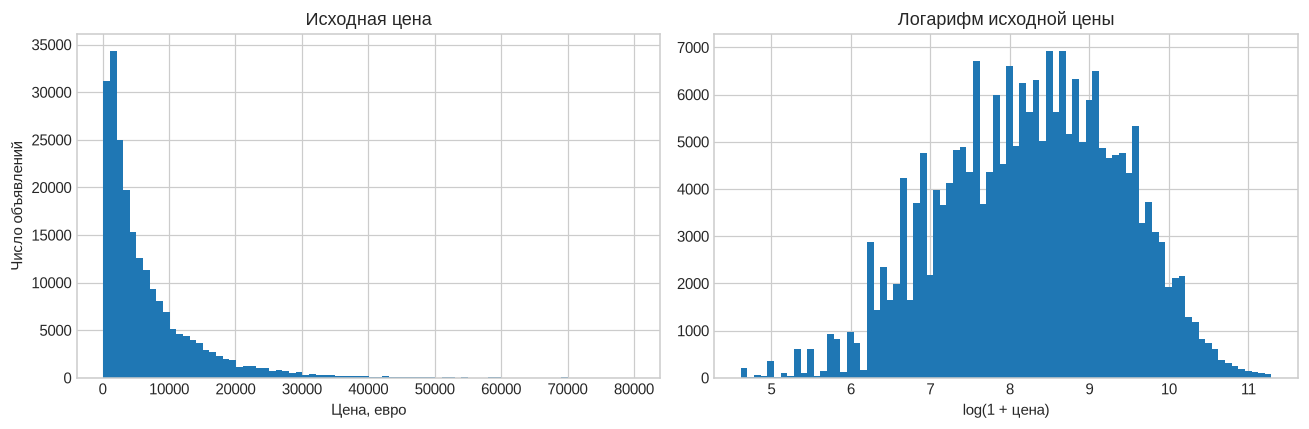

Осталось 0 из 241,190; удалено 241,190.


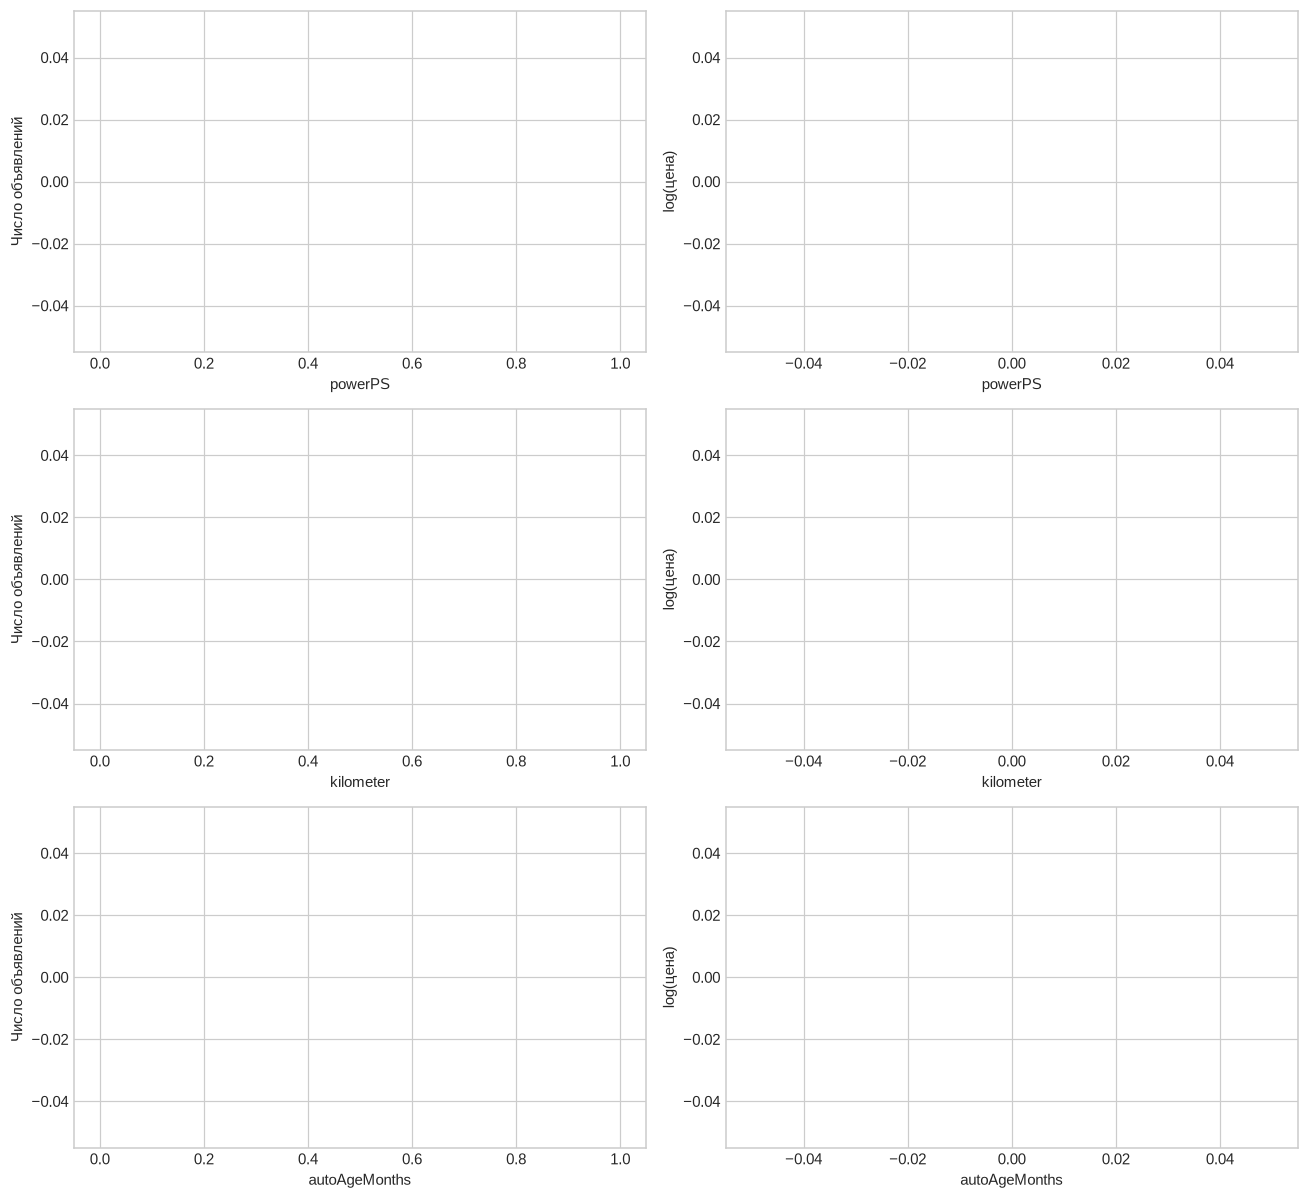

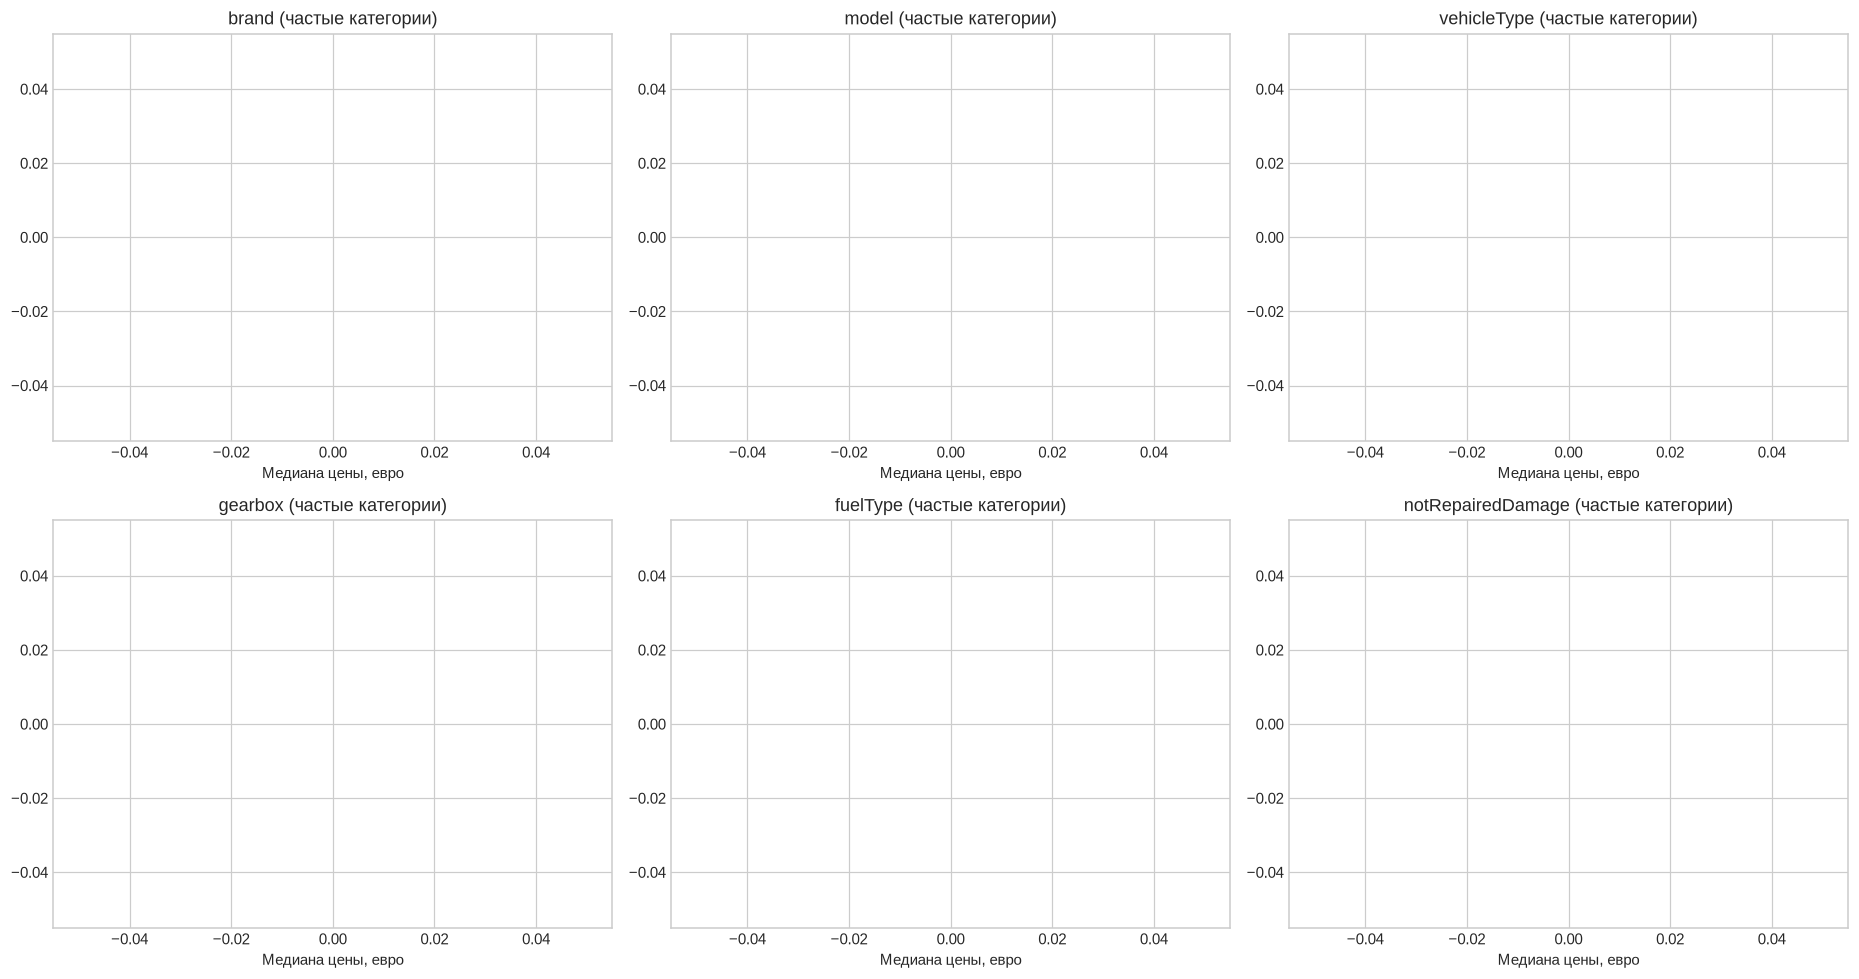

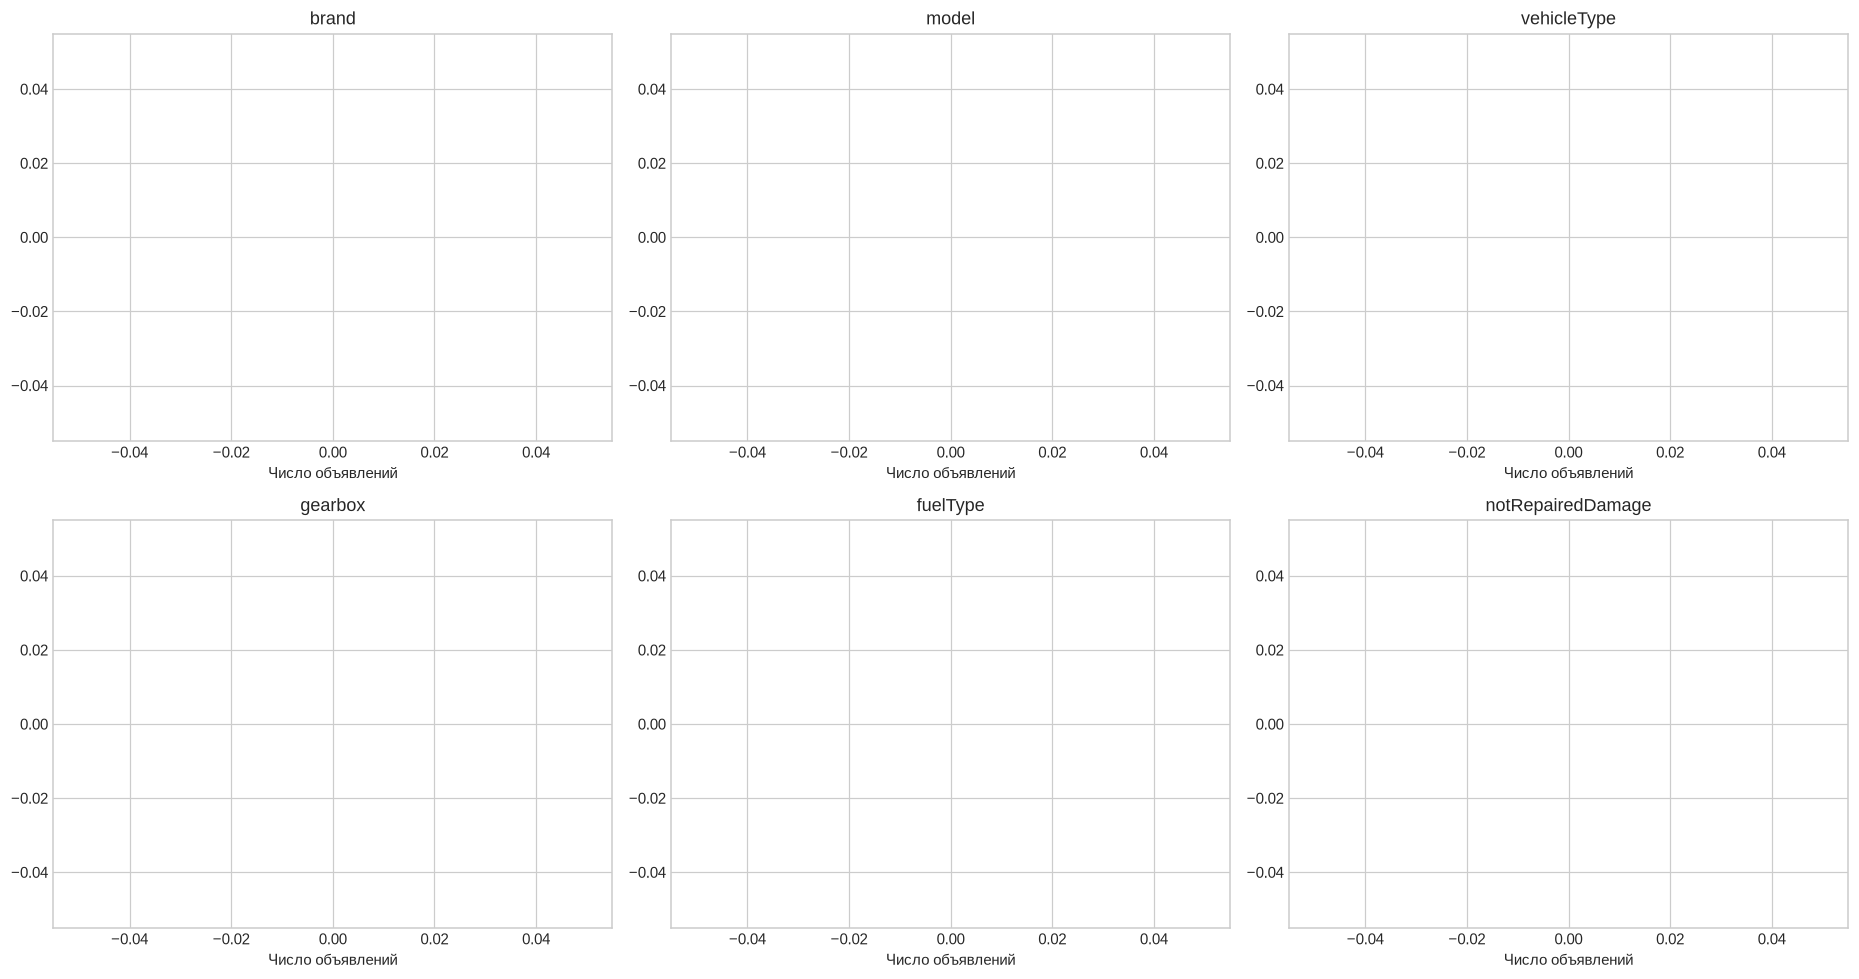

In [22]:
categorical = ['brand', 'model', 'vehicleType', 'gearbox', 'fuelType', 'notRepairedDamage']
numeric = ['powerPS', 'kilometer', 'autoAgeMonths']
other = []

profile = pd.DataFrame({'тип': data.dtypes.astype(str),
                        'пропуски': data.isna().sum(),
                        'уникальных': data.nunique()})
display(profile)
display(data[numeric + ['price']].describe(percentiles=[.01, .5, .95, .99]))
print('Полных дубликатов:', data.duplicated().sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(data['price'], bins=80)
axes[0].set(xlabel='Цена, евро', ylabel='Число объявлений', title='Исходная цена')
axes[1].hist(np.log1p(data['price']), bins=80)
axes[1].set(xlabel='log(1 + цена)', title='Логарифм исходной цены')
plt.tight_layout()
plt.show()

data = data.drop_duplicates().copy()
valid = (data['price'].between(100, 80_000)
         & data['powerPS'].between(50, 600)
         & data['kilometer'].between(5_000, 150_000)
         & data['autoAgeMonths'].between(1, 480))
data = data.loc[valid].reset_index(drop=True)
print(f'Осталось {len(data):,} из {len(raw_data):,}; удалено {len(raw_data) - len(data):,}.')

fig, axes = plt.subplots(3, 2, figsize=(12, 11))
plot_sample = data.sample(min(10_000, len(data)), random_state=42)
for row, feature in enumerate(numeric):
    axes[row, 0].hist(data[feature], bins=45)
    axes[row, 0].set(xlabel=feature, ylabel='Число объявлений')
    axes[row, 1].scatter(plot_sample[feature], np.log(plot_sample['price']), s=3, alpha=.15)
    axes[row, 1].set(xlabel=feature, ylabel='log(цена)')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, feature in zip(axes.flat, categorical):
    frequent = data[feature].value_counts().head(12).index
    medians = data.groupby(feature)['price'].median().reindex(frequent).sort_values()
    ax.barh(medians.index, medians.values)
    ax.set(title=feature + ' (частые категории)', xlabel='Медиана цены, евро')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, feature in zip(axes.flat, categorical):
    counts = data[feature].value_counts().head(12).sort_values()
    ax.barh(counts.index, counts.values)
    ax.set(title=feature, xlabel='Число объявлений')
plt.tight_layout()
plt.show()

data['powerPS'] = np.log1p(data['powerPS'])

**Обоснование подготовки данных.** Цены имеют правый хвост; логарифм уменьшает асимметрию и позволяет моделировать относительные изменения. Цены ниже 100 евро считаем символическими, выше 80 000 — отдельным премиальным сегментом. Это границы исследуемой задачи, а не утверждение, что каждый дорогой автомобиль ошибочен. Возраст старше 40 лет исключаем: коллекционные машины подчиняются другой зависимости цены от возраста. Мощность и пробег уже ограничены в исходном датасете; значения пробега 150 000 — верхняя категория, а не точное измерение и не основание удалять большую часть строк.

Возраст связан с убыванием цены, мощность — с её ростом; пробег также полезен, хотя закодирован грубыми категориями. Медианы по бренду, модели, кузову, коробке, топливу и повреждениям различаются, поэтому оставляем все шесть категориальных признаков. Столбец `model` имеет много категорий, что требует разреженного one-hot кодирования. Графики показывают описательные зависимости, а не причинное влияние: например, эффекты бренда и мощности смешаны.

Для мощности используем `log1p`, чтобы ослабить правый хвост и описать убывающую отдачу от дополнительных лошадиных сил. Возраст и пробег оставляем в исходной шкале: на графике связь возраста с логарифмом цены близка к линейной, а пробег уже задан грубыми категориями. Все три числовых признака затем стандартизируем через `StandardScaler`. Категории кодируем one-hot без придания им искусственного порядка; bias пропускаем без изменений. Пропусков нет. Полные дубликаты удаляем до разбиения; независимость разных объявлений одной и той же машины без идентификатора гарантировать нельзя.

Добавляем в данные единичную колонку `bias`, чтобы не делать отдельные параметр $b$ для свободного члена модели.

In [13]:
data['bias'] = 1.0
other = ['bias']
x = data[categorical + numeric + other]
y = np.log(data['price']).to_numpy()
# Основная задача далее — прогноз log(цены); евро-метрики считаем отдельно.

Теперь вам необходимо разбить данные на обучающую, тестовую и валидационную выборки.

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_holdout, y_train, y_holdout = train_test_split(x, y, test_size=.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=.5, random_state=42
)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
print('Размеры train / val / test:', len(y_train), len(y_val), len(y_test))
print('Доли:', np.round(np.array([len(y_train), len(y_val), len(y_test)]) / len(y), 4))
# Удаление полных дубликатов до split исключает их попадание в разные части.

Размеры train / val / test: 176929 22116 22117
Доли: [0.8 0.1 0.1]


А также сделаем базовую обработку данных, а именно:
* Применим `OneHotEncoding` к категориальным признакам
* Стандартизуем численные признаки с помощью `StandardScaler`
* Остальные признаки трогать не будем, т.к. с ними непонятно что делать

> А почему мы сначала делим данные, а только потом применяем обработку данных? Энкодеры и скейлеры используют информацию о данных: если сделать fit на всем датасете до split, это будет утечка: статистики из val/test попадут в обучение.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

column_transformer = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=True), categorical),
    ('scaling', StandardScaler(), numeric),
    ('other', 'passthrough', other),
], sparse_threshold=1.0)

X_train = column_transformer.fit_transform(X_train).tocsr()
X_val = column_transformer.transform(X_val).tocsr()
X_test = column_transformer.transform(X_test).tocsr()
assert np.all(X_train[:, -1].toarray() == 1)
print('Форма train:', X_train.shape, '; доля ненулевых:', X_train.nnz / np.prod(X_train.shape))
print('Категории и масштабирование обучены только на train.')

Форма train: (176929, 310) ; доля ненулевых: 0.03225806451612903
Категории и масштабирование обучены только на train.


## Задание 5. Сравнение методов градиентного спуска (1.5 балла)

В этом задании вам предстоит сравнить методы градиентного спуска на подготовленных вами данных из предыдущего задания.

### Задание 5.1. Подбор оптимальной длины шага (0.75 балла)

Подберите по валидационной выборке наилучшую длину шага $\lambda$ для каждого метода с точки зрения ошибки. Для этого сделайте перебор по логарифмической сетке. Для каждого метода посчитайте ошибку на обучающей и тестовой выборках, посчитайте качество по метрике $R^2$, сохраните количество итераций до сходимости.

Все параметры кроме `lambda_` стоит выставить равным значениям по умолчанию.

In [16]:
from time import perf_counter

METHODS = {
    'GD': VanillaGradientDescent, 'SGD': StochasticGradientDescent,
    'SAG': SAGDescent, 'Momentum': MomentumDescent, 'Adam': Adam,
}
LAMBDA_GRID = np.logspace(-3, 1, 9)
SEED = 42

def fit_candidate(method, lambda_, loss_factory=MSELoss, seed=SEED, **optimizer_kwargs):
    np.random.seed(seed)
    optimizer = METHODS[method](lr_schedule=TimeDecayLR(float(lambda_)), **optimizer_kwargs)
    model = CustomLinearRegression(optimizer, loss_factory())
    started = perf_counter()
    model.fit(X_train, y_train)
    elapsed = perf_counter() - started
    # Память SAG нужна во время обучения; обученная модель хранит веса и историю.
    if isinstance(optimizer, SAGDescent):
        optimizer.grad_memory = None
    return model, elapsed

def validation_mse(model):
    if not np.all(np.isfinite(model.w)) or not np.isfinite(model.loss_history[-1]):
        return np.inf
    prediction = model.predict(X_val)
    if not np.all(np.isfinite(prediction)):
        return np.inf
    with np.errstate(over='ignore'):
        return float(np.mean((prediction - y_val)**2))

def search(method, loss_factory=MSELoss, **optimizer_kwargs):
    records, best_model, best_value = [], None, np.inf
    for lambda_ in LAMBDA_GRID:
        model, seconds = fit_candidate(method, lambda_, loss_factory, **optimizer_kwargs)
        score = validation_mse(model)
        records.append({'метод': method, 'lambda': lambda_, 'val_MSE_log': score,
                        'итерации': model.optimizer.iteration,
                        'остановка': model.optimizer.stop_reason, 'секунды': seconds})
        if score < best_value:
            best_model, best_value = model, score
    if best_model is None:
        raise RuntimeError(f'Все кандидаты {method} разошлись')
    return best_model, pd.DataFrame(records)

def model_metrics(method, model):
    train_pred, test_pred = model.predict(X_train), model.predict(X_test)
    euro_pred = np.exp(np.clip(test_pred, -30, 30))
    return {'метод': method, 'lambda': model.optimizer.lr_schedule.lambda_,
            'train_MSE_log': mean_squared_error(y_train, train_pred),
            'val_MSE_log': validation_mse(model),
            'test_MSE_log': mean_squared_error(y_test, test_pred),
            'train_R2_log': r2_score(y_train, train_pred),
            'test_R2_log': r2_score(y_test, test_pred),
            'test_RMSE_euro': np.sqrt(mean_squared_error(np.exp(y_test), euro_pred)),
            'test_R2_euro': r2_score(np.exp(y_test), euro_pred),
            'итерации': model.optimizer.iteration,
            'остановка': model.optimizer.stop_reason}

best_models, search_tables = {}, []
for method in METHODS:
    best_models[method], trials = search(method)
    search_tables.append(trials)
    print(method, 'готов:', trials.loc[trials['val_MSE_log'].idxmin(), ['lambda', 'val_MSE_log', 'остановка']].to_dict())
search_results = pd.concat(search_tables, ignore_index=True)
results = pd.DataFrame([model_metrics(method, model) for method, model in best_models.items()])
display(results.round(5))
# Test используется для отчёта после выбора по val, не для подбора.
print('Логарифмическая сетка:', LAMBDA_GRID)

GD готов: {'lambda': 1.0, 'val_MSE_log': 0.2696721456920269, 'остановка': 'tolerance'}
SGD готов: {'lambda': 0.31622776601683794, 'val_MSE_log': 0.2844163948892623, 'остановка': 'max_iter'}
SAG готов: {'lambda': 1.0, 'val_MSE_log': 0.848395149742384, 'остановка': 'max_iter'}
Momentum готов: {'lambda': 1.0, 'val_MSE_log': 0.24816012757706118, 'остановка': 'tolerance'}
Adam готов: {'lambda': 3.1622776601683795, 'val_MSE_log': 0.24464056104745704, 'остановка': 'max_iter'}


,метод,lambda,train_MSE_log,val_MSE_log,test_MSE_log,train_R2_log,test_R2_log,test_RMSE_euro,test_R2_euro,итерации,остановка
0,GD,1.00000,0.26263,0.26967,0.26477,0.79184,0.78985,3762.34355,0.76821,406,tolerance
1,SGD,0.31623,0.27750,0.28442,0.27895,0.78005,0.77860,3874.34422,0.75420,1000,max_iter
2,SAG,1.00000,0.84663,0.84840,0.85033,0.32895,0.32511,5967.28232,0.41691,1000,max_iter
3,Momentum,1.00000,0.23979,0.24816,0.24448,0.80994,0.80596,4414.27472,0.68092,726,tolerance
4,Adam,3.16228,0.23578,0.24464,0.24009,0.81312,0.80945,4657.96515,0.64472,1000,max_iter


Логарифмическая сетка: [1.00000000e-03 3.16227766e-03 1.00000000e-02 3.16227766e-02
 1.00000000e-01 3.16227766e-01 1.00000000e+00 3.16227766e+00
 1.00000000e+01]


### Задание 5.2. Сравнение методов (0.75 балла)

Постройте график зависимости ошибки на обучающей выборке от номера итерации (все методы на одном графике).

Посмотрите на получившиеся результаты (таблички с метриками и график). Сравните методы между собой.

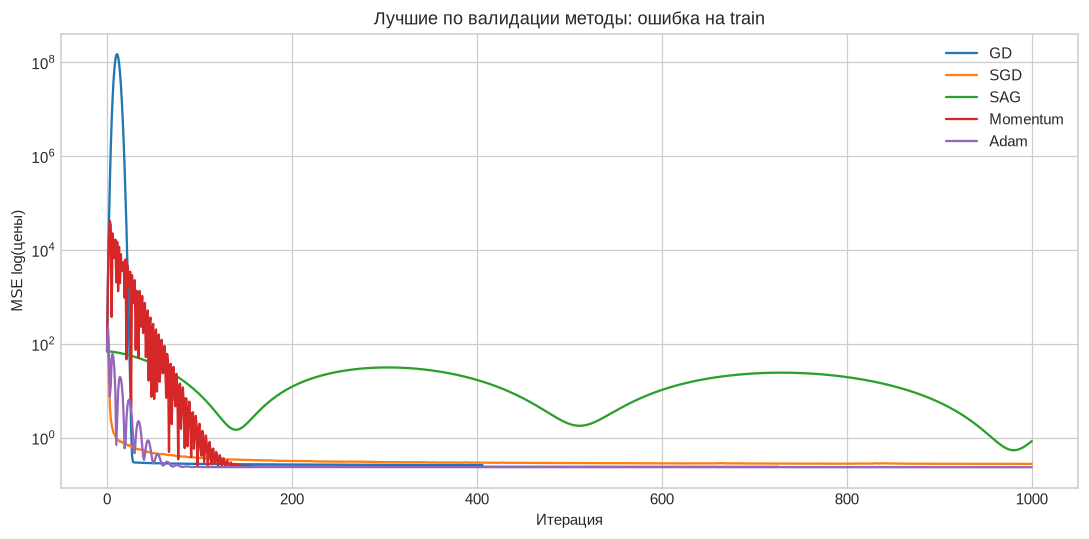

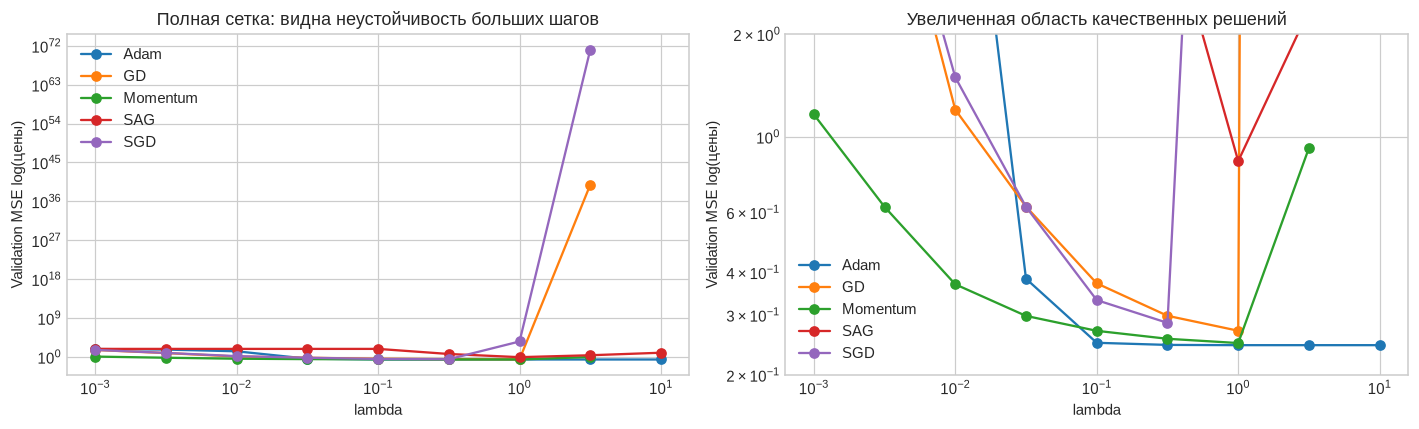

Лучший по validation MSE: Adam; test R²(log) = 0.8094.
Остановки: {'GD': 'tolerance', 'SGD': 'max_iter', 'SAG': 'max_iter', 'Momentum': 'tolerance', 'Adam': 'max_iter'}


In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
for method, model in best_models.items():
    ax.plot(model.loss_history, label=method)
ax.set(xlabel='Итерация', ylabel='MSE log(цены)', title='Лучшие по валидации методы: ошибка на train', yscale='log')
ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for method, trials in search_results.groupby('метод'):
    finite = trials[np.isfinite(trials['val_MSE_log'])]
    for ax in axes:
        ax.plot(finite['lambda'], finite['val_MSE_log'], marker='o', label=method)
for ax in axes:
    ax.set(xscale='log', yscale='log', xlabel='lambda', ylabel='Validation MSE log(цены)')
    ax.legend()
axes[0].set_title('Полная сетка: видна неустойчивость больших шагов')
axes[1].set(title='Увеличенная область качественных решений', ylim=(.2, 2.0))
plt.tight_layout()
plt.show()

winner = results.loc[results['val_MSE_log'].idxmin()]
print(f"Лучший по validation MSE: {winner['метод']}; test R²(log) = {winner['test_R2_log']:.4f}.")
print('Остановки:', results.set_index('метод')['остановка'].to_dict())

,метод,lambda,train_MSE_log,val_MSE_log,test_MSE_log,train_R2_log,test_R2_log,test_RMSE_euro,test_R2_euro,итерации,остановка,batch_size
0,SAG,1.00000,0.84663,0.8484,0.85033,0.32895,0.32511,5967.28232,0.41691,1000,max_iter,32
1,SAG,10.00000,0.46112,0.4686,0.46640,0.63451,0.62982,4840.37263,0.61635,1000,max_iter,256
2,SAG,3.16228,0.26015,0.2666,0.26345,0.79380,0.79090,3692.22787,0.77677,1000,max_iter,1024


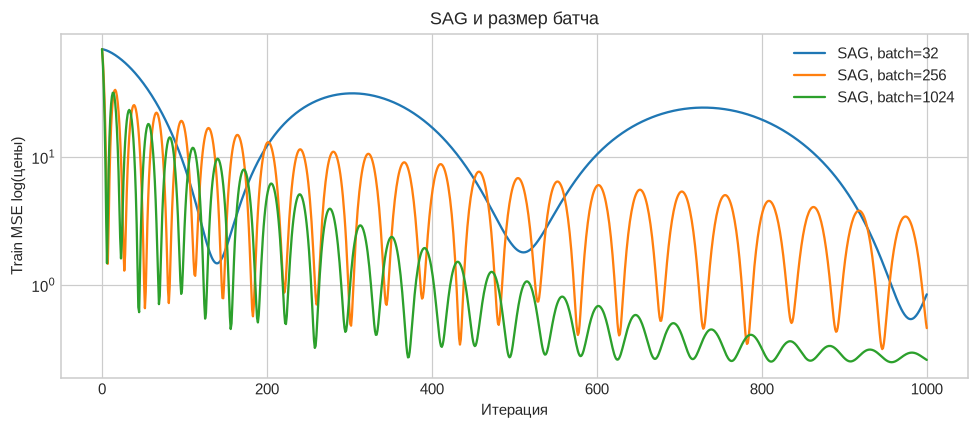

In [18]:
sag_batch_rows = [dict(model_metrics('SAG', best_models['SAG']), batch_size=32)]
sag_batch_models = {32: best_models['SAG']}
for batch_size in [256, 1024]:
    candidate, _ = search('SAG', batch_size=batch_size)
    sag_batch_models[batch_size] = candidate
    sag_batch_rows.append(dict(model_metrics('SAG', candidate), batch_size=batch_size))
sag_batch_results = pd.DataFrame(sag_batch_rows)
display(sag_batch_results.round(5))
fig, ax = plt.subplots(figsize=(9, 4))
for batch_size, model in sag_batch_models.items():
    ax.plot(model.loss_history, label=f'SAG, batch={batch_size}')
ax.set(xlabel='Итерация', ylabel='Train MSE log(цены)', yscale='log', title='SAG и размер батча')
ax.legend()
plt.tight_layout()
plt.show()

## Задание 6. Стохастический градиентный спуск и размер батча (1 балл)

В этом задании вам предстоит исследовать влияние размера батча на работу стохастического градиентного спуска.

* Сделайте по несколько запусков (например, $k = 10$) стохастического градиентного спуска на обучающей выборке для каждого размера батча из перебираемого списка. Замерьте время в секундах и количество итераций до сходимости. Посчитайте среднее этих значений для каждого размера батча.
* Постройте график зависимости количества шагов до сходимости от размера батча. _(под сходимостью понимается достижение критерия останова)_
* Постройте график зависимости времени до сходимости от размера батча.

Посмотрите на получившиеся результаты. Какие выводы можно сделать про подбор размера батча для стохастического градиентного спуска?

Готов batch_size = 1
Готов batch_size = 8
Готов batch_size = 32
Готов batch_size = 128
Готов batch_size = 512
Готов batch_size = 2048


,steps_mean,steps_std,seconds_mean,seconds_std,converged_fraction,val_MSE_mean
batch_size,,,,,,
1,297.3,176.68179,0.17396,0.03655,1.0,16.94859
8,1000.0,0.00000,0.27923,0.01023,0.0,0.31150
32,1000.0,0.00000,0.27641,0.00624,0.0,0.28973
128,1000.0,0.00000,0.30203,0.01900,0.0,0.28528
512,813.4,87.36030,0.31952,0.03029,1.0,0.28598
2048,439.2,21.72965,0.32732,0.01766,1.0,0.29374


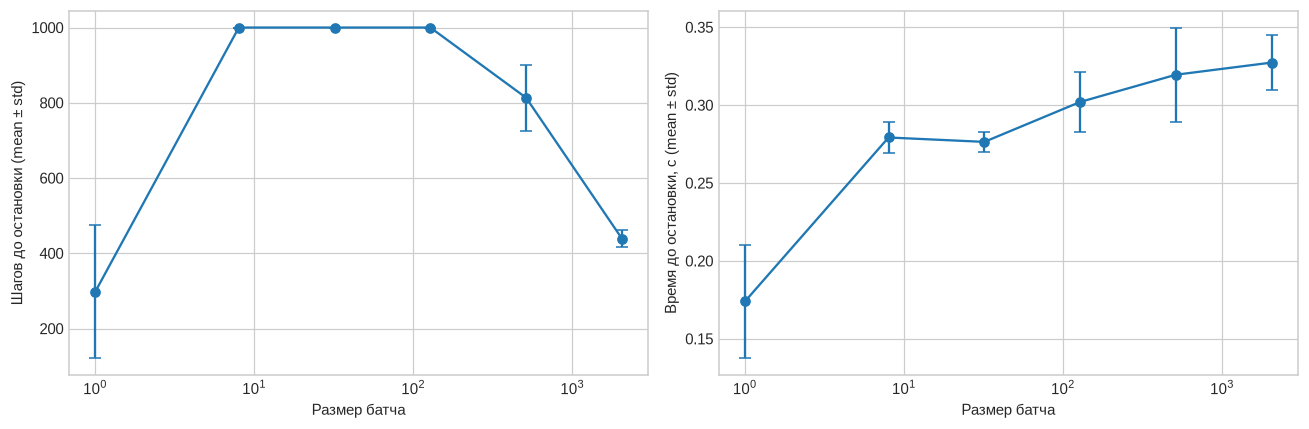

Доля запусков, достигших критерия tolerance, указана отдельно; max_iter не означает сходимость.


In [19]:
BATCH_SIZES = [1, 8, 32, 128, 512, 2048]
REPEATS = 10
sgd_lambda = best_models['SGD'].optimizer.lr_schedule.lambda_
batch_records = []
for batch_size in BATCH_SIZES:
    for repeat in range(REPEATS):
        model, seconds = fit_candidate('SGD', sgd_lambda, seed=100 + repeat, batch_size=batch_size)
        batch_records.append({'batch_size': batch_size, 'повтор': repeat,
                              'секунды': seconds, 'итерации': model.optimizer.iteration,
                              'сошёлся': model.optimizer.stop_reason == 'tolerance',
                              'val_MSE_log': validation_mse(model)})
    print('Готов batch_size =', batch_size)
batch_runs = pd.DataFrame(batch_records)
batch_summary = batch_runs.groupby('batch_size').agg(
    steps_mean=('итерации', 'mean'), steps_std=('итерации', 'std'),
    seconds_mean=('секунды', 'mean'), seconds_std=('секунды', 'std'),
    converged_fraction=('сошёлся', 'mean'), val_MSE_mean=('val_MSE_log', 'mean'),
)
display(batch_summary.round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].errorbar(batch_summary.index, batch_summary.steps_mean, yerr=batch_summary.steps_std, marker='o', capsize=4)
axes[0].set(xscale='log', xlabel='Размер батча', ylabel='Шагов до остановки (mean ± std)')
axes[1].errorbar(batch_summary.index, batch_summary.seconds_mean, yerr=batch_summary.seconds_std, marker='o', capsize=4)
axes[1].set(xscale='log', xlabel='Размер батча', ylabel='Время до остановки, с (mean ± std)')
plt.tight_layout()
plt.show()
print('Доля запусков, достигших критерия tolerance, указана отдельно; max_iter не означает сходимость.')

**Выводы.** При фиксированном шаге увеличение батча уменьшает дисперсию оценки градиента, но увеличивает стоимость одного обновления. Поэтому оптимальный размер выбирают совместно с шагом обучения и бюджетом вычислений. Показанные интервалы — стандартные отклонения по 10 запускам, не доверительные интервалы.

Критерий в задании проверяет величину одного обновления, а не близость к минимуму. Маленький случайный градиент или затухающий шаг могут привести к ранней остановке. В таблице отдельно приведены доля остановок по `tolerance` и качество: сравнивать только время или только число шагов недостаточно. Если запуск достиг 1000 шагов, его время — время до лимита, а не измеренное время до сходимости.

Замер охватывает весь `fit`, включая подготовку статистик MSE и сохранение истории ошибок. Это время данного процесса обучения, а не только вычисления градиента батча.

**Фактически в этих запусках:** батч 1 останавливался в среднем через 297.3 шага, но средняя validation MSE была **16.94859** — формальная остановка оказалась преждевременной. Батчи 8, 32 и 128 во всех повторах дошли до лимита. Батчи 512 и 2048 достигли tolerance за 813.4 и 439.2 шага в среднем, но заняли примерно 0.31 и 0.33 с: сокращение числа шагов не сократило полное время. Наименьшая средняя validation MSE среди проверенных батчей — **0.28528** при 128; у 512 она близка (**0.28598**). Поэтому в этом опыте разумен диапазон 128–512, а не автоматический выбор самого большого батча.

## Задание 7. Регуляризация (0.5 балла)

В этом задании вам предстоит исследовать влияние регуляризации на работу различных методов градиентного спуска. Напомним, регуляризация – это добавка к функции потерь, которая штрафует за норму весов. Мы будем использовать $L_2$-регуляризацию, таким образом функция потерь приобретает следующий вид:

$$
    Q(w) = \dfrac{1}{\ell} \sum\limits_{i=1}^{\ell} (a_w(x_i) - y_i)^2 + \dfrac{\mu}{2} \| w \|^2
$$

Допишите класс `linear_regression.L2Regularization`, следуя интерфейсу и докуметации.

Используя регуляризованный лосс в эксприментах, найдите лучшие параметры обучения с регуляризацией аналогично 5 заданию. Будем подбирать длину шага $\lambda$ (`lambda_`) и коэффициент регуляризации $\mu$ (`mu`).

Сравните для каждого метода результаты с регуляризацией и без регуляризации (нужно опять сохранить ошибку и качество по метрике $R^2$ на обучающей и тестовой выборках и количество итераций до сходимости).

Постройте для каждого метода график со значениями функции потерь MSE с регуляризацией и без регуляризации (всего должно получиться 5 графиков).

Посмотрите на получившиеся результаты. Какие можно сделать выводы, как регуляризация влияет на сходимость? Как изменилось качество на обучающей выборке? На тестовой? Чем вы можете объяснить это?

GD mu = 1e-05 ; val MSE = 0.26969
SGD mu = 1e-05 ; val MSE = 0.28442
SAG mu = 1e-05 ; val MSE = 0.84841
Momentum mu = 1e-05 ; val MSE = 0.24818
Adam mu = 1e-05 ; val MSE = 0.24473


,метод,lambda,train_MSE_log,val_MSE_log,test_MSE_log,train_R2_log,test_R2_log,test_RMSE_euro,test_R2_euro,итерации,остановка,режим,mu
9,Adam,3.16228,0.23587,0.24473,0.24018,0.81305,0.80937,4635.48253,0.64814,1000,max_iter,L2,0.00001
4,Adam,3.16228,0.23578,0.24464,0.24009,0.81312,0.80945,4657.96515,0.64472,1000,max_iter,без L2,0.00000
5,GD,1.00000,0.26265,0.26969,0.26479,0.79182,0.78984,3762.43931,0.76820,405,tolerance,L2,0.00001
0,GD,1.00000,0.26263,0.26967,0.26477,0.79184,0.78985,3762.34355,0.76821,406,tolerance,без L2,0.00000
8,Momentum,1.00000,0.23981,0.24818,0.24450,0.80992,0.80594,4409.43723,0.68162,722,tolerance,L2,0.00001
3,Momentum,1.00000,0.23979,0.24816,0.24448,0.80994,0.80596,4414.27472,0.68092,726,tolerance,без L2,0.00000
7,SAG,1.00000,0.84665,0.84841,0.85035,0.32893,0.32509,5967.29928,0.41691,1000,max_iter,L2,0.00001
2,SAG,1.00000,0.84663,0.84840,0.85033,0.32895,0.32511,5967.28232,0.41691,1000,max_iter,без L2,0.00000
6,SGD,0.31623,0.27750,0.28442,0.27895,0.78005,0.77860,3874.27663,0.75421,1000,max_iter,L2,0.00001
1,SGD,0.31623,0.27750,0.28442,0.27895,0.78005,0.77860,3874.34422,0.75420,1000,max_iter,без L2,0.00000


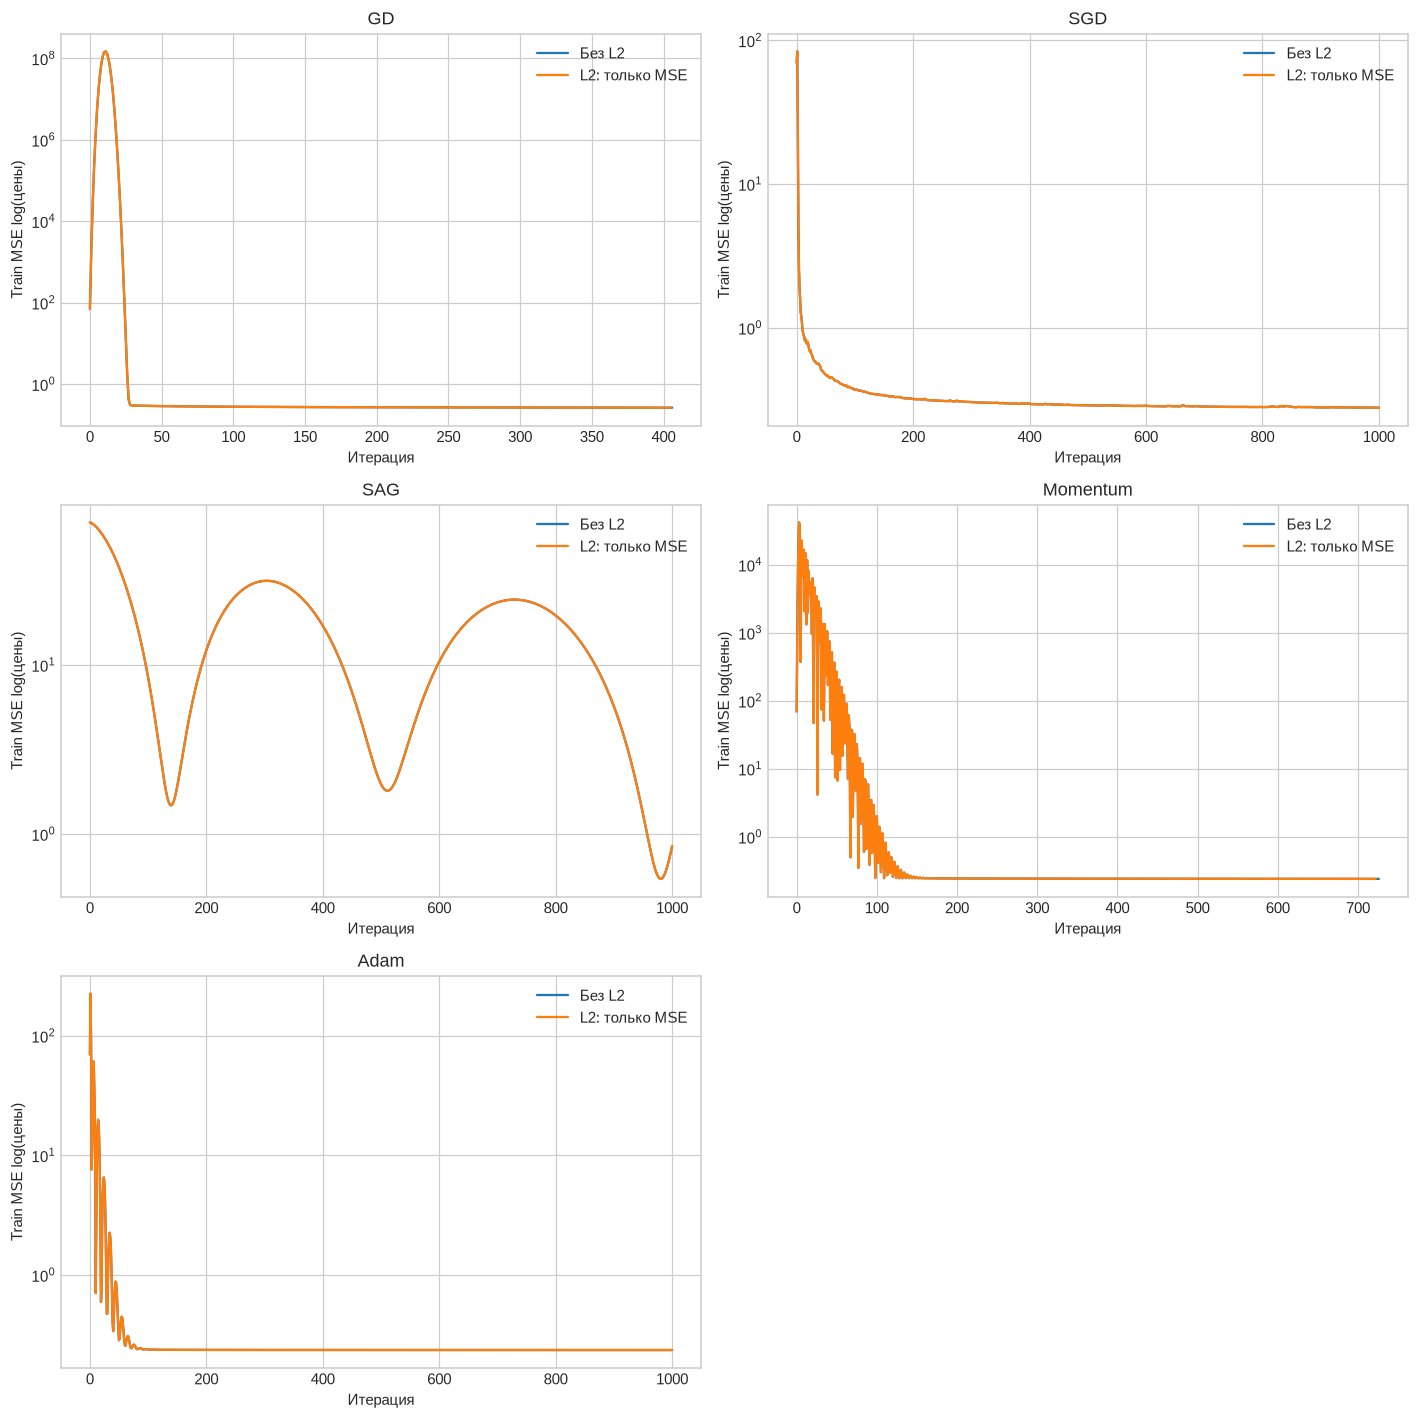

,метод,test_MSE_log_без,test_MSE_log_L2,изменение_test_MSE
0,GD,0.264773,0.264794,0.000021
1,SGD,0.278949,0.278950,0.000001
2,SAG,0.850326,0.850345,0.000020
3,Momentum,0.244478,0.244499,0.000022
4,Adam,0.240085,0.240177,0.000091


In [ ]:
MU_GRID = np.array([1e-5, 1e-3, 1e-1])
regularized_models, regularized_trials = {}, []
for method in METHODS:
    best_score, best_model = np.inf, None
    for mu in MU_GRID:
        model, trials = search(method, lambda mu=mu: L2Regularization(MSELoss(), mu_rate=mu))
        trials['mu'] = mu
        regularized_trials.append(trials)
        score = validation_mse(model)  
        if score < best_score:
            best_model, best_score = model, score
    regularized_models[method] = best_model
    print(method, 'mu =', best_model.loss_function.mu_rate, '; val MSE =', round(best_score, 5))
regularized_search = pd.concat(regularized_trials, ignore_index=True)
regularized_results = pd.DataFrame([
    dict(model_metrics(method, model), mu=model.loss_function.mu_rate)
    for method, model in regularized_models.items()
])
comparison = pd.concat([results.assign(режим='без L2', mu=0), regularized_results.assign(режим='L2')], ignore_index=True)
display(comparison.sort_values(['метод', 'режим']).round(5))

class MSETrackingL2(L2Regularization):
    def __init__(self, mu):
        super().__init__(MSELoss(), mu_rate=mu)
        self.mse_history = []

    def loss(self, X, y, w):
        value = self.core_loss.loss(X, y, w)
        self.mse_history.append(value)
        return value + self.mu_rate / 2 * float(w @ w)

fig, axes = plt.subplots(3, 2, figsize=(13, 13))
for ax, method in zip(axes.flat, METHODS):
    selected = regularized_models[method]
    tracked, _ = fit_candidate(method, selected.optimizer.lr_schedule.lambda_,
                               lambda selected=selected: MSETrackingL2(selected.loss_function.mu_rate))
    np.testing.assert_allclose(tracked.w, selected.w)
    ax.plot(best_models[method].loss_history, label='Без L2')
    ax.plot(tracked.loss_function.mse_history, label='L2: только MSE')
    ax.set(title=method, xlabel='Итерация', ylabel='Train MSE log(цены)', yscale='log')
    ax.legend()
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

l2_effect = results[['метод', 'test_MSE_log']].merge(
    regularized_results[['метод', 'test_MSE_log']], on='метод', suffixes=('_без', '_L2'))
l2_effect['изменение_test_MSE'] = l2_effect.test_MSE_log_L2 - l2_effect.test_MSE_log_без
display(l2_effect.round(6))

**Вывод.** Регуляризация добавляет к градиенту $\mu w$, а к гессиану MSE — $\mu I$. Она подавляет большие коэффициенты и устраняет вырождение из-за одновременного использования полного one-hot кодирования и bias. При подходящем шаге это может улучшить обусловленность, но одновременно меняет оптимум и допустимую длину шага. Поэтому гарантии уменьшения числа итераций нет.

Сравнение проводится по одинаковой MSE, а не по значениям разных целевых функций. При полном решении обеих задач минимум train MSE без штрафа не хуже регуляризованного; при остановке через конечное число шагов это соотношение может нарушаться. Уменьшение test MSE объясняется снижением дисперсии, увеличение — смещением или недостаточной оптимизацией. Знак и величина фактического эффекта для каждого метода приведены в последней таблице. Здесь штрафуется также bias, поскольку в условии задана норма **всего** $w$.

**Фактический эффект:** все методы выбрали минимальное ненулевое $\mu=10^{-5}$. Train MSE слегка выросла у всех пяти методов; test MSE также выросла: примерно на $2.1\cdot10^{-5}$ у GD, $1\cdot10^{-6}$ у SGD, $2.0\cdot10^{-5}$ у SAG, $2.2\cdot10^{-5}$ у Momentum и $9.1\cdot10^{-5}$ у Adam. Существенного улучшения обобщения здесь нет: объектов намного больше, чем признаков, а разрыв train/test невелик. Число шагов GD изменилось с 406 до 405, Momentum — с 726 до 722; остальные остались на лимите. При таком малом штрафе кривые почти совпадают, что видно на пяти графиках.

## Задание 8. Альтернативные функции потерь (1 балл)

В этом задании вам предстоит использовать другую функцию потерь для нашей задачи регрессии. В качестве функции потерь мы выбрали **LogCosh** и **HuberLoss**:

$$
    L(y, a)
    =
    \log\left(\cosh(a - y)\right).
$$

$$
L_{\text{Huber}}(y, a) = \frac{1}{n} \sum_{i=1}^{n}
\begin{cases}
   \frac{1}{2} (a_i - y_i)^2, & \text{если } |a_i - y_i| < \delta, \\
   \delta \cdot |a_i - y_i| - \frac{1}{2} \delta^2, & \text{если } |a_i - y_i| \geq \delta,
\end{cases}
$$

**Решение.** Пусть $r_i=x_i^Tw-y_i$, тогда $\nabla_w r_i=x_i$.

Для LogCosh:
$$\frac{d}{dr}\log\cosh r=\frac{1}{\cosh r}\sinh r=\tanh r,$$
$$dL=\frac1n\sum_i\tanh(r_i)x_i^Tdw,
\qquad {\nabla_w L=\frac1n X^T\tanh(Xw-y)}.$$
Вычисление лосса устойчиво: $\log\cosh r=\operatorname{logaddexp}(r,-r)-\log 2$.

Для Huber ($\delta>0$):
$$\frac{d}{dr}\frac12r^2=r \quad (|r|<\delta),$$
$$\frac{d}{dr}\left(\delta|r|-\frac12\delta^2\right)=\delta\operatorname{sign}(r)
\quad (|r|>\delta).$$
В точках $r=\pm\delta$ левые и правые производные совпадают. Значит,
$$\psi_\delta(r)=\begin{cases}r,& |r|<\delta,\\\delta\operatorname{sign}(r),& |r|\ge\delta,\end{cases}
=\operatorname{clip}(r,-\delta,\delta),$$
$${\nabla_w L_{Huber}=\frac1nX^T\psi_\delta(Xw-y)}.$$
У MSE производная по остатку неограниченна, а у этих лоссов ограниченна, что снижает влияние крупных ошибок.

Программно реализуйте функции потерь и их градиенты для LogCosh и HuberLoss в файле `linear_regression.py`. После этого обучите все пять методов градиентного спуска (без регуляризации) с этими лоссами аналогично заданию 5 и сравните качество с результатами из задания 5, где использовался MSE.

Имплементировать эти функции потерь необходимо при помощи наследования от `linear_regression.LossFunction` и имплементирования всех абстрактных методов. Аналитическое решение для этих функций выводить и имплементировать не требуется.



LogCosh GD готов
LogCosh SGD готов
LogCosh SAG готов
LogCosh Momentum готов
LogCosh Adam готов
Huber GD готов
Huber SGD готов
Huber SAG готов
Huber Momentum готов
Huber Adam готов


,метод,lambda,train_MSE_log,val_MSE_log,test_MSE_log,train_R2_log,test_R2_log,test_RMSE_euro,test_R2_euro,итерации,остановка,loss
14,Adam,10.00000,0.23965,0.24783,0.24411,0.81005,0.80625,4287.31660,0.69901,653,tolerance,Huber
9,Adam,10.00000,0.23936,0.24749,0.24388,0.81028,0.80643,4291.24993,0.69846,580,tolerance,LogCosh
4,Adam,3.16228,0.23578,0.24464,0.24009,0.81312,0.80945,4657.96515,0.64472,1000,max_iter,MSE
10,GD,10.00000,0.25231,0.25936,0.25647,0.80001,0.79645,3724.80145,0.77281,882,tolerance,Huber
5,GD,10.00000,0.25276,0.25981,0.25690,0.79966,0.79610,3693.50492,0.77661,805,tolerance,LogCosh
0,GD,1.00000,0.26263,0.26967,0.26477,0.79184,0.78985,3762.34355,0.76821,406,tolerance,MSE
13,Momentum,10.00000,0.24176,0.24962,0.24638,0.80837,0.80445,4135.15260,0.72000,1000,max_iter,Huber
8,Momentum,10.00000,0.24092,0.24886,0.24550,0.80904,0.80515,4160.15150,0.71660,1000,max_iter,LogCosh
3,Momentum,1.00000,0.23979,0.24816,0.24448,0.80994,0.80596,4414.27472,0.68092,726,tolerance,MSE
12,SAG,3.16228,5.80049,5.83214,5.82890,-3.59758,-3.62634,210675.75216,-725.79085,1000,max_iter,Huber


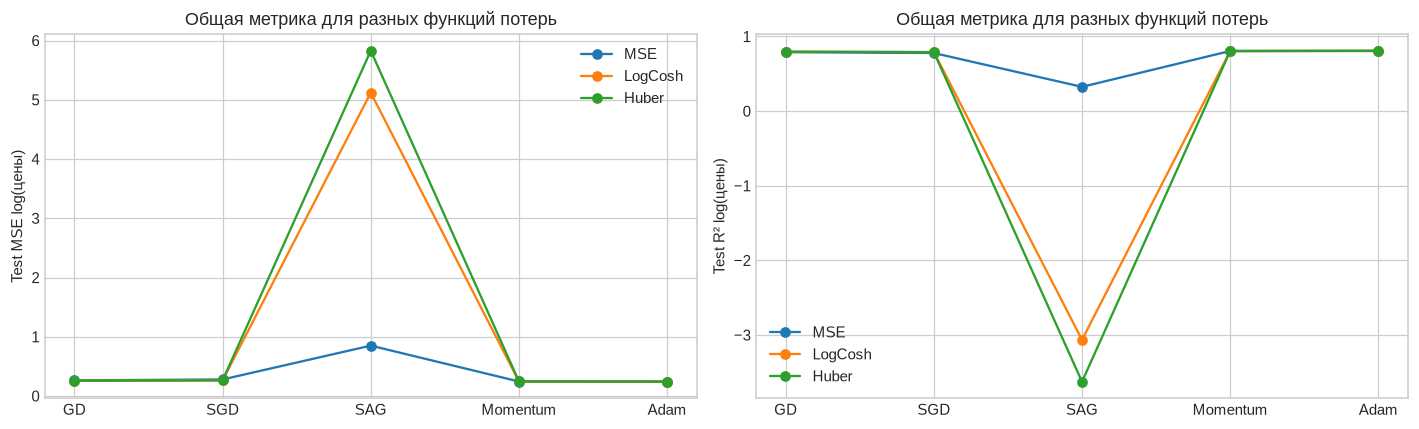

In [21]:
alternative_models, alternative_tables = {}, []
for loss_name, loss_factory in [('LogCosh', LogCoshLoss), ('Huber', HuberLoss)]:
    for method in METHODS:
        model, _ = search(method, loss_factory)
        alternative_models[(loss_name, method)] = model
        alternative_tables.append(dict(model_metrics(method, model), loss=loss_name))
        print(loss_name, method, 'готов')
alternative_results = pd.concat([
    results.assign(loss='MSE'), pd.DataFrame(alternative_tables)
], ignore_index=True)
display(alternative_results.sort_values(['метод', 'loss']).round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for loss_name, group in alternative_results.groupby('loss', sort=False):
    axes[0].plot(group['метод'], group['test_MSE_log'], marker='o', label=loss_name)
    axes[1].plot(group['метод'], group['test_R2_log'], marker='o', label=loss_name)
axes[0].set(ylabel='Test MSE log(цены)', title='Общая метрика для разных функций потерь')
axes[1].set(ylabel='Test R² log(цены)', title='Общая метрика для разных функций потерь')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

**Вывод.** Для каждого из двух лоссов перебрана та же сетка $\lambda$ по validation MSE, без регуляризации, со стандартным $\delta=1$ у Huber. Прямое сравнение значений LogCosh, Huber и MSE некорректно из-за разного масштаба и формы: в таблице и на графиках сравниваются одинаковые MSE и $R^2$.

Ограниченная производная уменьшает влияние крупных остатков, но не гарантирует меньшую MSE, поскольку критерий обучения отличается от критерия оценки. Логарифмирование цены уже снижает влияние дорогих автомобилей, поэтому дополнительная устойчивость может дать небольшой или отрицательный эффект. Кроме того, при одинаковом лимите итераций различается степень оптимизации. Евро-метрики приведены отдельно: экспонента прогноза логарифма не является несмещённой оценкой условного среднего цены.

**Численное сравнение (MSE логарифма цены):**

- **GD**: test MSE — Huber: 0.25647, LogCosh: 0.25690, MSE: 0.26477; по validation среди этих лоссов выбран **Huber**.
- **SGD**: test MSE — Huber: 0.26420, LogCosh: 0.26298, MSE: 0.27895; по validation среди этих лоссов выбран **LogCosh**.
- **SAG**: test MSE — Huber: 5.82890, LogCosh: 5.12083, MSE: 0.85033; по validation среди этих лоссов выбран **MSE**.
- **Momentum**: test MSE — Huber: 0.24638, LogCosh: 0.24550, MSE: 0.24448; по validation среди этих лоссов выбран **MSE**.
- **Adam**: test MSE — Huber: 0.24411, LogCosh: 0.24388, MSE: 0.24009; по validation среди этих лоссов выбран **MSE**.

В этом запуске устойчивые лоссы улучшили MSE для GD и SGD, а для Momentum и Adam лучшим остался MSE. У SAG с батчем 32 оба устойчивых лосса дали отрицательный test R² и дошли до лимита: это плохо оптимизированные модели при данных настройках, а не свидетельство общей непригодности этих лоссов. Для многих устойчивых вариантов выбран шаг 10 — верхняя точка сетки; выводы относятся к проверенному диапазону и бюджету итераций.